In [1]:
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button

from scipy.integrate import quad

import config
import constantes
import profiles 
import contraction
import general

/Users/baptistesevilla/Documents/Ecole/Physique/Master/M2/Stage Dark matter/Code/profiles.py:293: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  val, _ = quad(integrand, 0.0, np.inf, limit=constantes.ABEL_LIMIT, epsrel=epsrel, epsabs= constantes.ABEL_EPSABS)


In [2]:
fig = 8

plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

In [3]:
halo = profiles.Halo(
    halo_mass = config.HALO_MASS, 
    concentration = config.CONCENTRATION, 
    rho_c = constantes.RHO_C, 
    z = constantes.Z, 
    omega_m = constantes.OMEGA_M, 
    omega_l = constantes.OMEGA_L, 
    alpha = constantes.ALPHA_EINASTO)
# NFW 
rho_dm_nfw =  halo.density_nfw(config.R)

rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f = contraction.contract_Schneider2015()

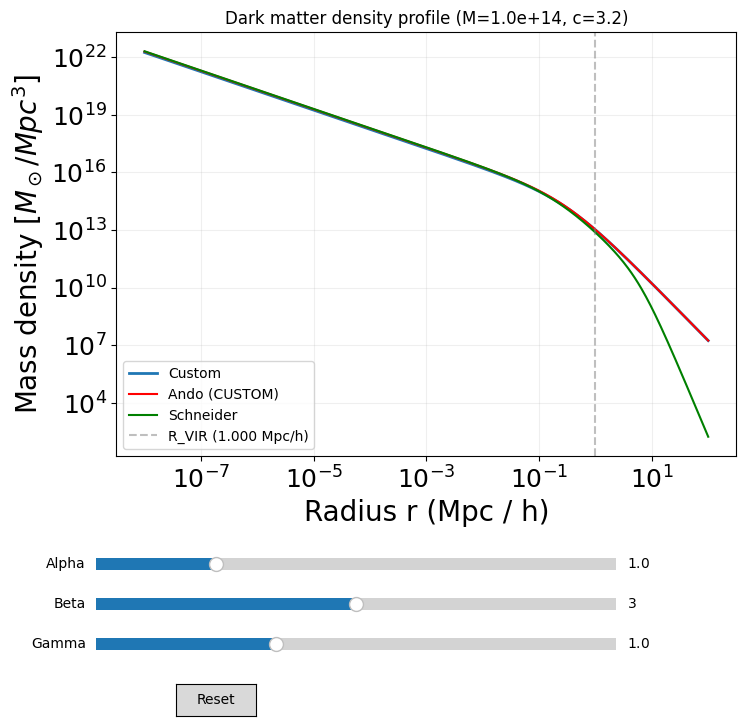

In [4]:
def dimensionless_profile(x, alpha, beta, gamma):
    x = np.where(x == 0, 1e-10, x)
    return 1.0 / ((x**gamma) * (1 + x**alpha)**((beta - gamma) / alpha))

def calc_density_fixed_mass(r, M_vir, c, R_vir, alpha, beta, gamma):
    r_s = R_vir / c

    def integrand(x):
        return (x**2) * dimensionless_profile(x, alpha, beta, gamma)
    
    integral_val, _ = quad(integrand, 1e-10, c)
    rho_0 = M_vir / (4 * np.pi * (r_s**3) * integral_val)
    x = r / r_s
    return rho_0 * dimensionless_profile(x, alpha, beta, gamma)


R_VIR_FIXED = 1.0   
r_s_fixed = R_VIR_FIXED / config.CONCENTRATION 

alpha_init = 1.0
beta_init = 3.0
gamma_init = 1.0


fig, ax = plt.subplots(figsize=(fig, fig))


plt.subplots_adjust(bottom=0.35)

rho = calc_density_fixed_mass(config.R, config.HALO_MASS, config.CONCENTRATION, R_VIR_FIXED, alpha_init, beta_init, gamma_init)
[line] = ax.loglog(config.R, rho / constantes.H, lw=2, label='Custom')

plt.loglog(config.R, rho_dm_nfw / constantes.H, label=f'Ando ({config.DM_PROFILE.upper()})', color='red')
plt.loglog(config.R, initial_components["rho_i_dm"], label='Schneider', color='green')
plt.axvline(x=R_VIR_FIXED, color='grey', linestyle='--', alpha=0.5, label=f'R_VIR ({R_VIR_FIXED:.3f} Mpc/h)')

ax.set_xlabel('Radius r (Mpc / h)')
ax.set_ylabel(r'Mass density $[M_\odot / Mpc^3]$')
ax.set_title(f'Dark matter density profile (M={config.HALO_MASS:.1e}, c={config.CONCENTRATION})')
ax.grid(True, which="both", ls="-", alpha=0.2)
ax.legend()

ax_alpha = plt.axes([0.1, 0.20, 0.65, 0.03])
ax_beta  = plt.axes([0.1, 0.15, 0.65, 0.03])
ax_gamma = plt.axes([0.1, 0.10, 0.65, 0.03])

slider_alpha = Slider(ax_alpha, 'Alpha', 0.1, 4.0, valinit=alpha_init)
slider_beta  = Slider(ax_beta, 'Beta', 1.0, 5.0, valinit=beta_init)
slider_gamma = Slider(ax_gamma, 'Gamma', 0.0, 2.9, valinit=gamma_init) 
# Note : gamma est limite a 2.9 car si gamma >= 3, l'integrale de masse diverge.

def update(val):
    a = slider_alpha.val
    b = slider_beta.val
    g = slider_gamma.val
    
    y_new = calc_density_fixed_mass(config.R, config.HALO_MASS, config.CONCENTRATION, R_VIR_FIXED, a, b, g)
    line.set_ydata(y_new/ constantes.H)
    
    ax.relim()
    ax.autoscale_view()
    
    fig.canvas.draw_idle()

slider_alpha.on_changed(update)
slider_beta.on_changed(update)
slider_gamma.on_changed(update)

resetax = plt.axes([0.2, 0.025, 0.1, 0.04])
button = Button(resetax, 'Reset', hovercolor='0.975')

def reset(event):
    slider_alpha.reset()
    slider_beta.reset()
    slider_gamma.reset()

button.on_clicked(reset)

plt.show()

In [5]:
R_200 = (3.0 * config.HALO_MASS / (4.0 * np.pi * 200.0 * constantes.RHO_C))**(1.0/3.0)
R_S = R_200 / config.CONCENTRATION

delta_c = (200.0 / 3.0) * (config.CONCENTRATION**3) / (np.log(1.0 + config.CONCENTRATION) - (config.CONCENTRATION / (1.0 + config.CONCENTRATION)))
rho_0_derived = (constantes.RHO_C * delta_c) / 1e18


if config.DM_PROFILE == 'NFW':
    rho = (1.0 - constantes.F_B) * halo.density_nfw(config.R)
    
elif config.DM_PROFILE == 'Einasto':
    rho = (1.0 - constantes.F_B) * halo.density_einasto(config.R)
    
elif config.DM_PROFILE == 'Burkert':
    rho = (1.0 - constantes.F_B) * halo.density_burkert(config.R)
    
elif config.DM_PROFILE == 'Custom':
    rho = calc_density_fixed_mass(
        r=config.R, 
        M_vir=config.HALO_MASS, 
        c=config.CONCENTRATION, 
        R_vir=R_200, 
        alpha=config.ALPHA_CUSTOM, 
        beta=config.BETA_CUSTOM, 
        gamma=config.GAMMA_CUSTOM
    )

In [6]:
rho_bcm, rho_rdm, rho_baryons, initial_components, m_baryon_f_array, r_f = contraction.contract_Schneider2015()

In [7]:


rho_nfw = (1.0 - constantes.F_B) * halo.density_nfw(config.R)


rho_einasto = (1.0 - constantes.F_B) * halo.density_einasto(config.R)


rho_burkert = (1.0 - constantes.F_B) * halo.density_burkert(config.R)


rho_custom = calc_density_fixed_mass(
    r=config.R, 
    M_vir=config.HALO_MASS, 
    c=config.CONCENTRATION, 
    R_vir=R_200, 
    alpha=config.ALPHA_CUSTOM, 
    beta=config.BETA_CUSTOM, 
    gamma=config.GAMMA_CUSTOM
    )

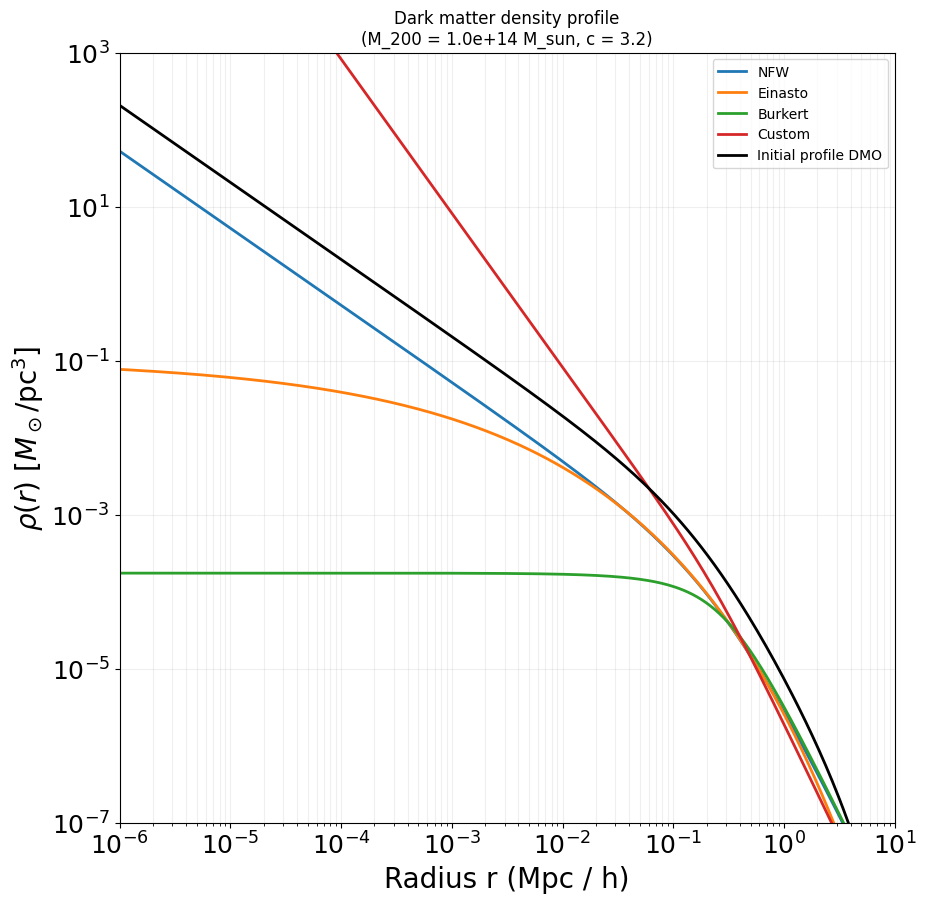

In [8]:
factor = constantes.CONVERSION_FACTOR

plt.figure(figsize=(10, 10))

plt.loglog(config.R, rho_nfw /factor, lw=2, label='NFW')
plt.loglog(config.R, rho_einasto /factor, lw=2, label='Einasto')
plt.loglog(config.R, rho_burkert /factor, lw=2, label='Burkert')
plt.loglog(config.R, rho_custom / factor , lw=2, label='Custom')


plt.loglog(config.R, initial_components["rho_i_dm"]  / 1e18, label='Initial profile DMO', color='black', linewidth=2)

plt.xlabel('Radius r (Mpc / h)')
plt.ylabel(r'$\rho(r)\ [M_\odot/\mathrm{pc}^3 ]$')
plt.title(f'Dark matter density profile\n(M_200 = {config.HALO_MASS:.1e} M_sun, c = {config.CONCENTRATION})')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.xlim(1e-6,10)
plt.ylim(1e-7,1e3)
plt.legend()

plt.show()

In [9]:
halo = general.contract_halo()
r = halo['r']
r_s = halo['r_s']

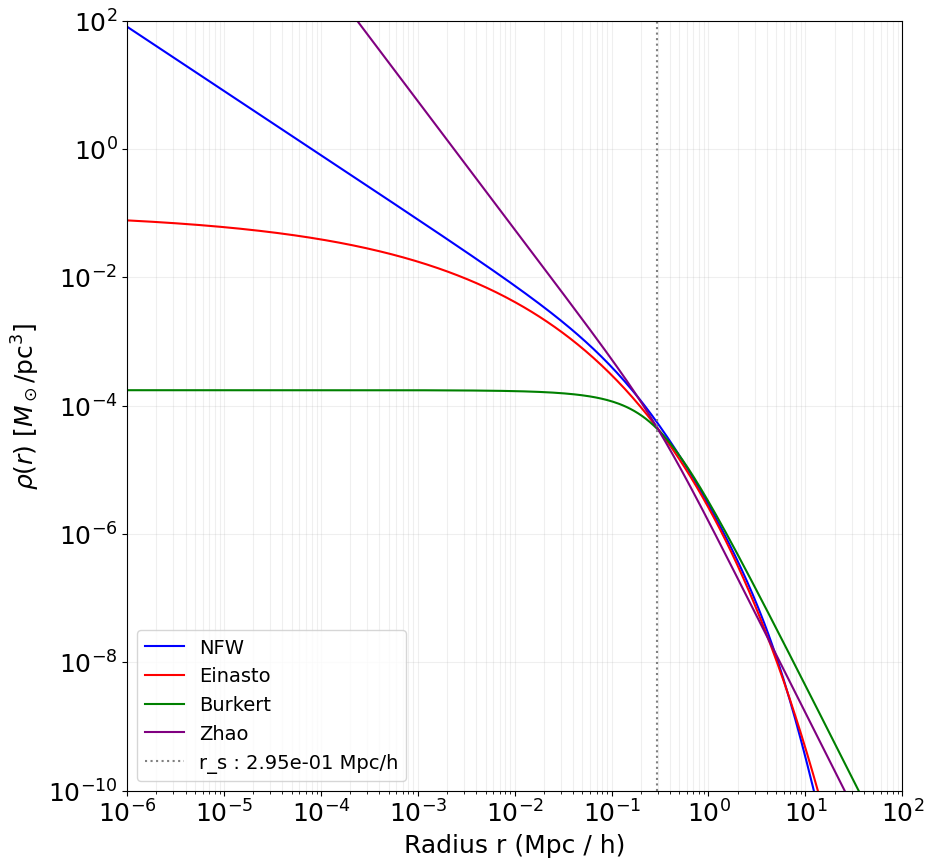

In [10]:
config.DM_PROFILE = 'NFW'
NFW = general.contract_halo()
r_nfw = NFW['r']
dm_nfw = NFW['rho_dm_initial']

config.DM_PROFILE = 'Einasto'
Einasto = general.contract_halo()
r_einasto = Einasto['r']
dm_einasto = Einasto['rho_dm_initial']

config.DM_PROFILE = 'Burkert'
Burkert = general.contract_halo()
r_burkert = Burkert['r']
dm_burkert = Burkert['rho_dm_initial']

config.DM_PROFILE = 'PIEMD'
PIEMD = general.contract_halo()
r_PIEMD = PIEMD['r']
dm_PIEMD = PIEMD['rho_dm_initial']

config.DM_PROFILE = 'Custom'
Custom = general.contract_halo()
r_Custom = Custom['r']
dm_Custom = Custom['rho_dm_initial']

plt.figure(figsize=(10, 10))

plt.loglog(r_nfw, dm_nfw, label='NFW', color='blue')
plt.loglog(r_einasto, dm_einasto, label='Einasto', color='red')
plt.loglog(r_burkert, dm_burkert, label='Burkert', color='green')
# plt.loglog(r_PIEMD, dm_PIEMD, label='PIEMD', color='magenta')
plt.loglog(r_Custom, dm_Custom, label='Zhao', color='purple')
plt.axvline(r_s, label=f'r_s : {r_s:.2e} Mpc/h', c='grey', ls=':')

plt.xlabel('Radius r (Mpc / h)',fontsize=18)
plt.ylabel(r'$\rho(r)\ [M_\odot/\mathrm{pc}^3 ]$',fontsize=18)
#plt.title(f'Dark matter density profile\n(M_200 = {config.HALO_MASS:.1e} M_sun, c = {config.CONCENTRATION})')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.xlim(1e-6,1e2)
plt.ylim(1e-10,1e2)
plt.legend(fontsize=14)

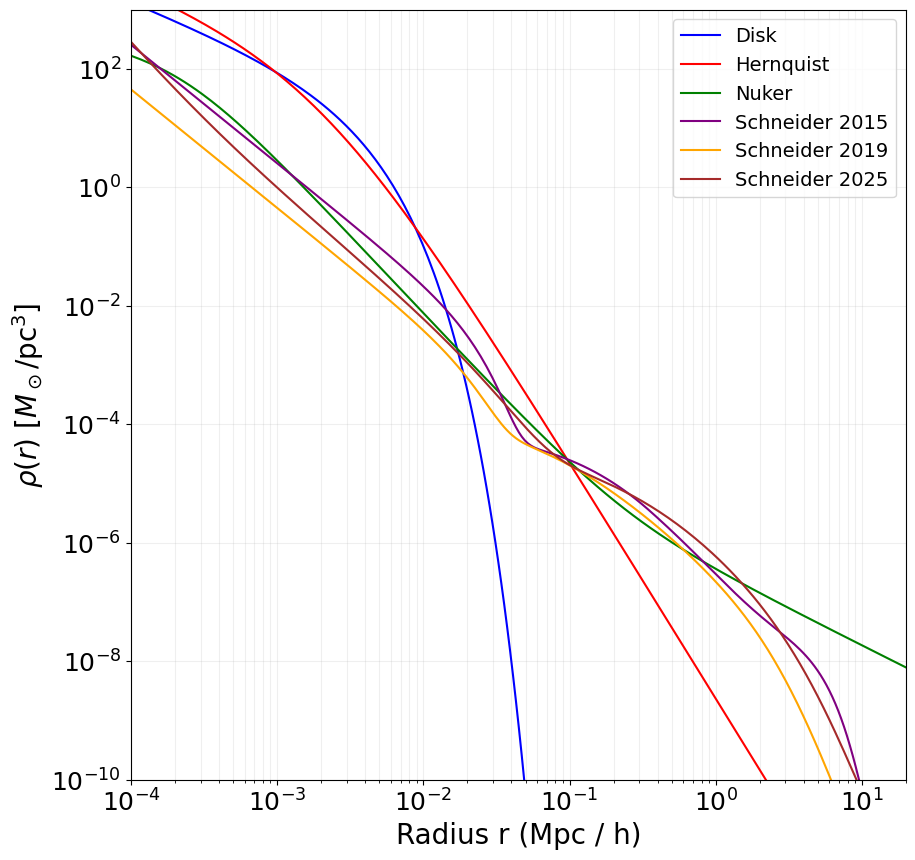

In [11]:
config.BARYON_PROFILE = 'Disk'
Disk = general.contract_halo()
r_Disk = Disk['r']
b_Disk = Disk['rho_baryons']

config.BARYON_PROFILE = 'Hernquist'
Hernquist = general.contract_halo()
r_Hernquist = Hernquist['r']
b_Hernquist = Hernquist['rho_baryons']

config.BARYON_PROFILE = 'Nuker'
Nuker = general.contract_halo()
r_Nuker = Nuker['r']
b_Nuker = Nuker['rho_baryons']

config.BARYON_PROFILE = 'Schneider2015'
Schneider2015 = general.contract_halo()
r_Schneider2015 = Schneider2015['r']
b_Schneider2015 = Schneider2015['rho_baryons']

config.BARYON_PROFILE = 'Schneider2019'
Schneider2019 = general.contract_halo()
r_Schneider2019 = Schneider2019['r']
b_Schneider2019 = Schneider2019['rho_baryons']

config.BARYON_PROFILE = 'Schneider2025'
Schneider2025 = general.contract_halo()
r_Schneider2025 = Schneider2025['r']
b_Schneider2025 = Schneider2025['rho_baryons']

config.BARYON_PROFILE = 'Interpolated'
Interpolated = general.contract_halo()
r_Interpolated = Interpolated['r']
b_Interpolated = Interpolated['rho_baryons']

plt.figure(figsize=(10, 10))

plt.loglog(r_Disk, b_Disk, label='Disk', color='blue')
plt.loglog(r_Hernquist, b_Hernquist, label='Hernquist', color='red')
plt.loglog(r_Nuker, b_Nuker, label='Nuker', color='green')
plt.loglog(r_Schneider2015, b_Schneider2015, label='Schneider 2015', color='purple')
plt.loglog(r_Schneider2019, b_Schneider2019, label='Schneider 2019', color='orange')
plt.loglog(r_Schneider2025, b_Schneider2025, label='Schneider 2025', color='brown')
#plt.loglog(r_Interpolated, b_Interpolated, label='Interpolated', color='black')

plt.xlabel('Radius r (Mpc / h)')
plt.ylabel(r'$\rho(r)\ [M_\odot/\mathrm{pc}^3 ]$')
#plt.title(f'Dark matter density profile\n(M_200 = {config.HALO_MASS:.1e} M_sun, c = {config.CONCENTRATION})')
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.xlim(1e-4,2e1)
plt.ylim(1e-10,1e3)
plt.legend(fontsize = 14)
plt.show()